# Clasificación de Automóviles
## Árbol de Decisión y Bosque Aleatorio

Este notebook entrena y evalúa dos modelos de clasificación sobre el dataset de automóviles:
- **Árbol de Decisión** (`DecisionTreeClassifier`)
- **Bosque Aleatorio** (`RandomForestClassifier`)

**Variable objetivo:** `class` — evaluación del automóvil (`unacc`, `acc`, `good`, `vgood`)

---
## 1. Importaciones

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from category_encoders import OrdinalEncoder

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.preprocessing import LabelEncoder

import warnings
warnings.filterwarnings('ignore')

# Estilo de gráficas
sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.dpi'] = 100

---
## 2. Carga y Exploración del Dataset

In [2]:
df = pd.read_csv('automoviles.csv')
print('Dimensiones:', df.shape)
df.head(10)

Dimensiones: (1728, 7)


,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
5,vhigh,vhigh,2,2,med,high,unacc
6,vhigh,vhigh,2,2,big,low,unacc
7,vhigh,vhigh,2,2,big,med,unacc
8,vhigh,vhigh,2,2,big,high,unacc
9,vhigh,vhigh,2,4,small,low,unacc


In [3]:
print('Tipos de datos:')
print(df.dtypes)
print()
print('Valores nulos por columna:')
print(df.isnull().sum())

Tipos de datos:
buying      str
maint       str
doors       str
persons     str
lug_boot    str
safety      str
class       str
dtype: object

Valores nulos por columna:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64


In [4]:
print('Valores únicos por columna:')
for col in df.columns:
    print(f'  {col}: {df[col].unique().tolist()}')

Valores únicos por columna:
  buying: ['vhigh', 'high', 'med', 'low']
  maint: ['vhigh', 'high', 'med', 'low']
  doors: ['2', '3', '4', '5more']
  persons: ['2', '4', 'more']
  lug_boot: ['small', 'med', 'big']
  safety: ['low', 'med', 'high']
  class: ['unacc', 'acc', 'vgood', 'good']


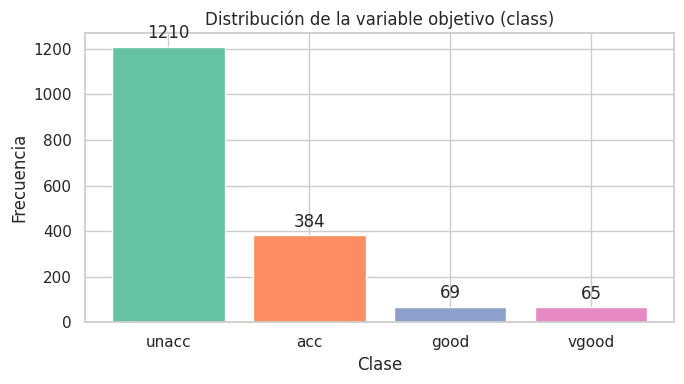

In [5]:
# Distribución de la clase objetivo
fig, ax = plt.subplots(figsize=(7, 4))
class_counts = df['class'].value_counts()
bars = ax.bar(class_counts.index, class_counts.values, color=sns.color_palette('Set2', len(class_counts)))
ax.bar_label(bars, padding=3)
ax.set_title('Distribución de la variable objetivo (class)')
ax.set_xlabel('Clase')
ax.set_ylabel('Frecuencia')
plt.tight_layout()
plt.savefig('distribucion_clase.png', dpi=100)
plt.show()

---
## 3. Preprocesamiento

Todas las variables son categóricas ordinales. Se usa `OrdinalEncoder` de `category_encoders` para respetar el orden natural de cada atributo.

In [6]:
# Definir el orden natural de cada variable categórica ordinal
ordinal_mapping = [
    {'col': 'buying',   'mapping': {'low': 0, 'med': 1, 'high': 2, 'vhigh': 3}},
    {'col': 'maint',    'mapping': {'low': 0, 'med': 1, 'high': 2, 'vhigh': 3}},
    {'col': 'doors',    'mapping': {'2': 0, '3': 1, '4': 2, '5more': 3}},
    {'col': 'persons',  'mapping': {'2': 0, '4': 1, 'more': 2}},
    {'col': 'lug_boot', 'mapping': {'small': 0, 'med': 1, 'big': 2}},
    {'col': 'safety',   'mapping': {'low': 0, 'med': 1, 'high': 2}},
]

df_enc = df.copy()

# Convertir a string por si alguna columna llegó como int
for item in ordinal_mapping:
    col = item['col']
    df_enc[col] = df_enc[col].astype(str).map(item['mapping'])

# Codificar la variable objetivo
le = LabelEncoder()
df_enc['class'] = le.fit_transform(df_enc['class'])
print('Clases codificadas:', dict(zip(le.classes_, le.transform(le.classes_))))

df_enc.head()

Clases codificadas: {'acc': np.int64(0), 'good': np.int64(1), 'unacc': np.int64(2), 'vgood': np.int64(3)}


,buying,maint,doors,persons,lug_boot,safety,class
0,3,3,0,0,0,0,2
1,3,3,0,0,0,1,2
2,3,3,0,0,0,2,2
3,3,3,0,0,1,0,2
4,3,3,0,0,1,1,2


In [7]:
# Separar features y target
X = df_enc.drop(columns=['class'])
y = df_enc['class']

# División entrenamiento / prueba (80 / 20), estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Entrenamiento: {X_train.shape[0]} muestras')
print(f'Prueba:        {X_test.shape[0]} muestras')

Entrenamiento: 1382 muestras
Prueba:        346 muestras


---
## 4. Modelo 1 — Árbol de Decisión

In [8]:
dt = DecisionTreeClassifier(random_state=42, max_depth=6)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)
print(f'Exactitud (Árbol de Decisión): {acc_dt:.4f}')

Exactitud (Árbol de Decisión): 0.9451


In [9]:
print('Reporte de Clasificación — Árbol de Decisión')
print(classification_report(y_test, y_pred_dt, target_names=le.classes_))

Reporte de Clasificación — Árbol de Decisión
              precision    recall  f1-score   support

         acc       0.87      0.88      0.88        77
        good       0.70      1.00      0.82        14
       unacc       0.99      0.98      0.98       242
       vgood       0.90      0.69      0.78        13

    accuracy                           0.95       346
   macro avg       0.87      0.89      0.87       346
weighted avg       0.95      0.95      0.95       346



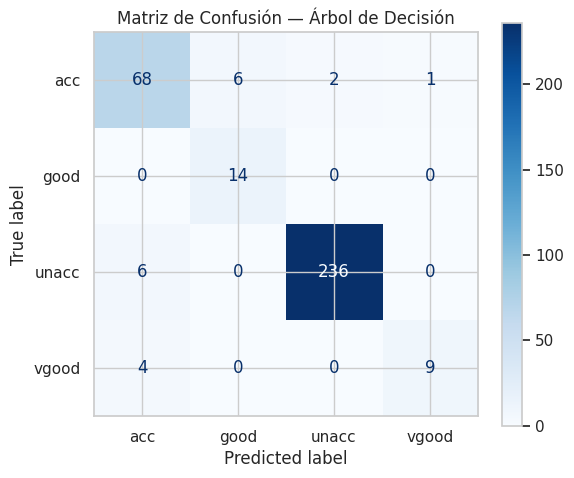

In [10]:
# Matriz de confusión — Árbol de Decisión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt,
    display_labels=le.classes_,
    cmap='Blues', ax=ax
)
ax.set_title('Matriz de Confusión — Árbol de Decisión')
plt.tight_layout()
plt.savefig('confusion_dt.png', dpi=100)
plt.show()

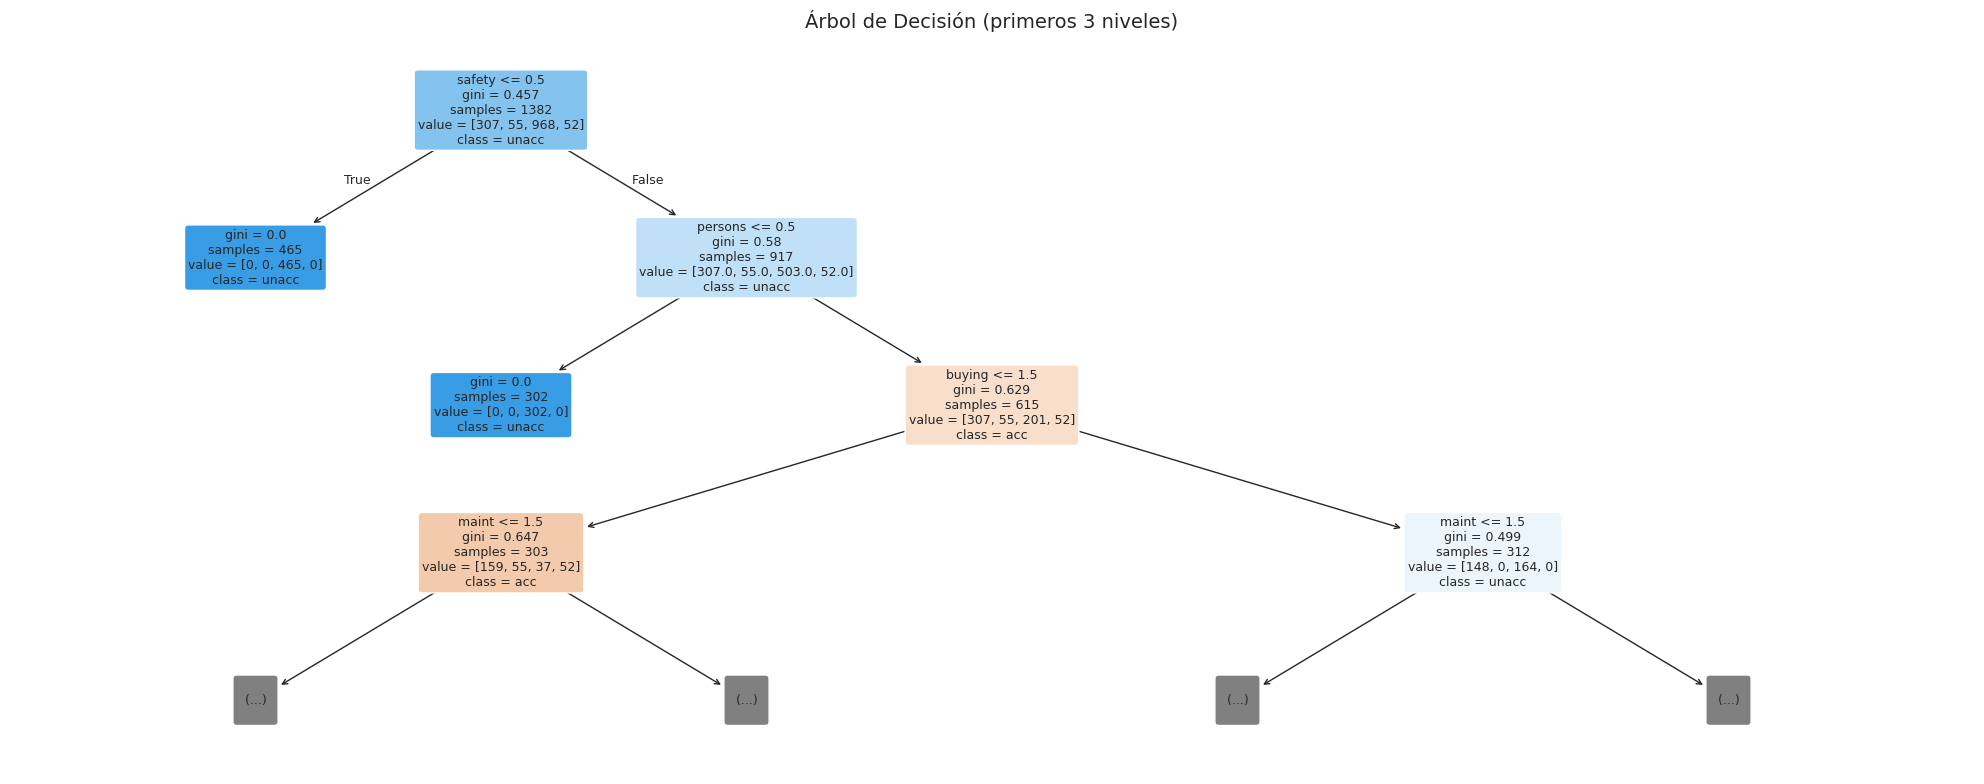

In [11]:
# Visualización del árbol (profundidad limitada para legibilidad)
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(
    dt,
    feature_names=X.columns.tolist(),
    class_names=le.classes_,
    filled=True, rounded=True,
    max_depth=3, ax=ax, fontsize=9
)
ax.set_title('Árbol de Decisión (primeros 3 niveles)', fontsize=14)
plt.tight_layout()
plt.savefig('arbol_decision.png', dpi=100)
plt.show()

In [12]:
# Validación cruzada — Árbol de Decisión
cv_scores_dt = cross_val_score(dt, X, y, cv=5, scoring='accuracy')
print(f'CV Exactitud (5-fold) — Árbol de Decisión:')
print(f'  Media:  {cv_scores_dt.mean():.4f}')
print(f'  Desv:   {cv_scores_dt.std():.4f}')
print(f'  Scores: {np.round(cv_scores_dt, 4)}')

CV Exactitud (5-fold) — Árbol de Decisión:
  Media:  0.7645
  Desv:   0.0802
  Scores: [0.7977 0.7081 0.6474 0.8812 0.7884]


---
## 5. Modelo 2 — Bosque Aleatorio

In [13]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f'Exactitud (Bosque Aleatorio): {acc_rf:.4f}')

Exactitud (Bosque Aleatorio): 0.9855


In [14]:
print('Reporte de Clasificación — Bosque Aleatorio')
print(classification_report(y_test, y_pred_rf, target_names=le.classes_))

Reporte de Clasificación — Bosque Aleatorio
              precision    recall  f1-score   support

         acc       0.95      1.00      0.97        77
        good       0.93      0.93      0.93        14
       unacc       1.00      1.00      1.00       242
       vgood       1.00      0.77      0.87        13

    accuracy                           0.99       346
   macro avg       0.97      0.92      0.94       346
weighted avg       0.99      0.99      0.99       346



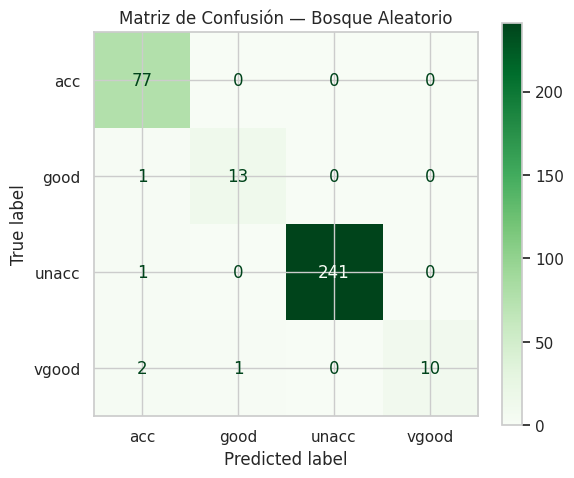

In [15]:
# Matriz de confusión — Bosque Aleatorio
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=le.classes_,
    cmap='Greens', ax=ax
)
ax.set_title('Matriz de Confusión — Bosque Aleatorio')
plt.tight_layout()
plt.savefig('confusion_rf.png', dpi=100)
plt.show()

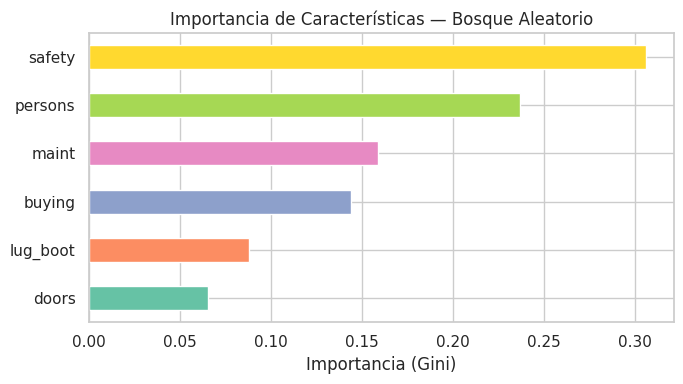

In [16]:
# Importancia de características — Bosque Aleatorio
importancias = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
importancias.plot(kind='barh', ax=ax, color=sns.color_palette('Set2', len(importancias)))
ax.set_title('Importancia de Características — Bosque Aleatorio')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.savefig('importancia_features.png', dpi=100)
plt.show()

In [17]:
# Validación cruzada — Bosque Aleatorio
cv_scores_rf = cross_val_score(rf, X, y, cv=5, scoring='accuracy')
print(f'CV Exactitud (5-fold) — Bosque Aleatorio:')
print(f'  Media:  {cv_scores_rf.mean():.4f}')
print(f'  Desv:   {cv_scores_rf.std():.4f}')
print(f'  Scores: {np.round(cv_scores_rf, 4)}')

CV Exactitud (5-fold) — Bosque Aleatorio:
  Media:  0.8212
  Desv:   0.0531
  Scores: [0.7168 0.8584 0.8497 0.8522 0.829 ]


---
## 6. Comparación de Modelos

In [18]:
resultados = pd.DataFrame({
    'Modelo': ['Árbol de Decisión', 'Bosque Aleatorio'],
    'Exactitud (Test)': [acc_dt, acc_rf],
    'CV Media (5-fold)': [cv_scores_dt.mean(), cv_scores_rf.mean()],
    'CV Desv. Est.': [cv_scores_dt.std(), cv_scores_rf.std()],
})
resultados = resultados.set_index('Modelo')
resultados.round(4)

,Exactitud (Test),CV Media (5-fold),CV Desv. Est.
Modelo,,,
Árbol de Decisión,0.9451,0.7645,0.0802
Bosque Aleatorio,0.9855,0.8212,0.0531


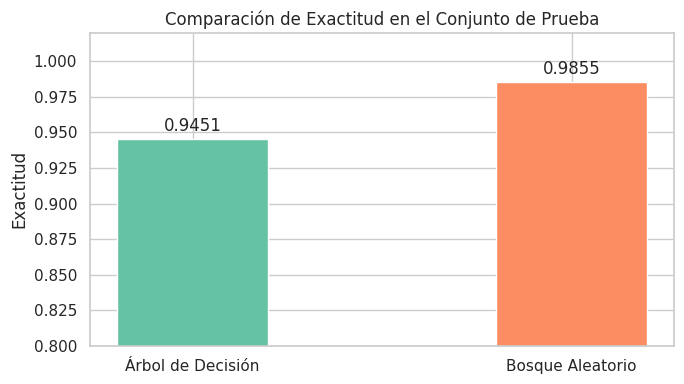

In [19]:
# Gráfica comparativa
fig, ax = plt.subplots(figsize=(7, 4))
modelos = ['Árbol de Decisión', 'Bosque Aleatorio']
exactitudes = [acc_dt, acc_rf]
colores = sns.color_palette('Set2', 2)

bars = ax.bar(modelos, exactitudes, color=colores, width=0.4)
ax.bar_label(bars, fmt='%.4f', padding=3)
ax.set_ylim(0.8, 1.02)
ax.set_title('Comparación de Exactitud en el Conjunto de Prueba')
ax.set_ylabel('Exactitud')
plt.tight_layout()
plt.savefig('comparacion_modelos.png', dpi=100)
plt.show()

---
## 7. Conclusiones

| Aspecto | Árbol de Decisión | Bosque Aleatorio |
|---|---|---|
| Interpretabilidad | ✅ Alta | ⚠️ Baja |
| Exactitud típica | Moderada | Alta |
| Riesgo de sobreajuste | Alto | Bajo |
| Velocidad de entrenamiento | Rápida | Moderada |

El **Bosque Aleatorio** generalmente supera al Árbol de Decisión gracias al ensamble de múltiples árboles que reduce la varianza. Sin embargo, el Árbol de Decisión es preferible cuando la **interpretabilidad** del modelo es prioritaria.